# Demo: what data we have so far (temporary)

Replicating **Mukherjee, Panayotov & Shon (2021), "Eye in the sky: Private satellites and government macro data"** (JFE).

**The paper's idea in one paragraph.** Private satellites can estimate US oil inventories by photographing storage tanks, but only when the sky is clear. The EIA announces official inventories every Wednesday. If satellites already told the market the answer (clear weeks), oil prices barely react to the announcement. If clouds blocked the view (cloudy weeks), the announcement is news and prices move. So **cloud cover over ten key oil storage hubs** is the instrument that identifies the effect.

**What this notebook covers (steps 1-3 of our plan, no tick data yet):**
1. Which weather stations stand in for the ten hubs
2. The raw NOAA weather data and how sky cover is decoded
3. Hourly → daily → weekly **cloudiness** and the *cloudy-week* dummy
4. Looking at the hubs from space (NASA GIBS / MODIS and Sentinel-2) to see what "cloudy" means

Everything runs from the `project/` folder. The scripts that produced the data are `config.py`, `01_select_stations.py`, `02_download_isd.py`, `03_cloudiness.py` (see the last section for how to re-run them).

In [1]:
import sys
sys.path.insert(0, ".")          # so we can import config.py and viz.py from this folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config as C
import viz

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Sample period: {C.START_YEAR}-{C.END_YEAR}   (change START_YEAR / END_YEAR in config.py)")

Sample period: 2014-2018   (change START_YEAR / END_YEAR in config.py)


## 1. The ten hubs and their weather stations

The paper uses the airport weather station nearest to each of ten oil storage hubs (footnote 9). `01_select_stations.py` finds candidates and `03_cloudiness.py` keeps the nearest one with at least 80% usable daylight sky readings. Some first choices failed (e.g. Sheppard AFB is not on the NOAA bucket), so a few hubs use the 2nd or 3rd nearest airport.

In [2]:
chosen = pd.read_csv(C.OUT / "chosen_stations.csv", dtype={"usaf": str, "wban": str})
chosen

,hub,usaf,wban,icao,km,completeness
0,"Cushing, OK",720357,53993,KCUH,3.9,0.936
1,"Patoka, IL",724330,03879,KSLO,16.2,0.962
2,"Clovelly, LA",722041,12993,KGAO,2.0,0.865
3,"Saint James, LA",722310,12916,KMSY,52.2,0.994
4,"Houston, TX",722440,12918,KHOU,15.3,0.999
5,"Beaumont-Nederland, TX",722410,12917,KBPT,5.8,0.996
6,"Corpus Christi, TX",722510,12924,KCRP,11.5,0.998
7,"Midland, TX",722650,23023,KMAF,13.5,0.999
8,"Wink, TX",722656,23040,KINK,5.9,0.963
9,"Wichita Falls, TX",720404,00134,KCWC,6.7,0.855


## 2. Raw data: NOAA ISD hourly observations

Each file is one station-year (`data/isd/<usaf><wban>_<year>.csv`, downloaded by `02_download_isd.py`). The columns we use:
- `DATE` is in **UTC**, so we convert to local time (US Central) before taking the 07:00-18:00 daylight window
- `GA1` is the first cloud layer, `"coverage,quality,base height,quality,type,quality"`
- `REM` is the raw METAR text, handy for sanity checks

In [3]:
raw = pd.read_csv(C.ISD_DIR / "72035753993_2018.csv",
                  usecols=["DATE", "REPORT_TYPE", "GA1", "GA2", "REM"], dtype=str)   # Cushing airport, 2018
raw[raw.DATE.str.startswith("2018-06-01T1") & raw.REPORT_TYPE.str.contains("FM-15")].head(5)

,DATE,REPORT_TYPE,GA1,GA2,REM
10920,2018-06-01T10:15:00,FM-15,"04,5,+02134,5,99,9",NaN,MET08606/01/18 04:15:02 METAR KCUH 011015Z 000...
10921,2018-06-01T10:35:00,FM-15,"00,5,+99999,9,99,9",NaN,MET08306/01/18 04:35:02 METAR KCUH 011035Z 000...
10922,2018-06-01T10:55:00,FM-15,"04,5,+02134,5,99,9",NaN,MET08606/01/18 04:55:01 METAR KCUH 011055Z 000...
10923,2018-06-01T11:15:00,FM-15,"04,5,+01981,5,99,9",NaN,MET08806/01/18 05:15:02 METAR KCUH 011115Z 000...
10924,2018-06-01T11:35:00,FM-15,"04,5,+01981,5,99,9",NaN,MET08606/01/18 05:35:02 METAR KCUH 011135Z 000...


`GA1`'s first number is the sky cover in **oktas** (eighths of the sky): 0 = clear, 8 = fully overcast. Dividing by 8 gives a 0-1 cloudiness. (Using only the first layer reproduces the paper's Table 1 numbers; taking the max over layers makes the sky look too cloudy. See `SKY_LAYERS` in `config.py`.)

In [4]:
oktas = pd.to_numeric(raw.GA1.str.split(",").str[0], errors="coerce")
cover = (oktas / 8).where(oktas <= 8)                # 9 = obscured, 10 = partial, 99 = missing -> handled in 03
pd.DataFrame({"oktas": oktas, "cover": cover}).dropna().groupby("oktas").agg(n_obs=("cover", "size"), cover=("cover", "first"))

,n_obs,cover
oktas,,
0.0,15754,0.000
4.0,3642,0.500
7.0,1751,0.875
8.0,4232,1.000


## 3. Hourly → daily → weekly cloudiness

Pipeline in `03_cloudiness.py`:
1. per station: mean sky cover within each local hour, daylight hours only (07:00-18:00)
2. per day: mean over daylight hours (need ≥ 6 hours), then mean across the ten hubs
3. per week: window from the Thursday before the Friday inventory date to the Tuesday before the Wednesday announcement
4. a week is **cloudy** if its cloudiness is above the 75th percentile of the sample

**`hourly_station.csv`**: one column per hub, one row per daylight hour.

In [5]:
hourly = pd.read_csv(C.OUT / "hourly_station.csv", index_col="hour", parse_dates=True)
print(hourly.shape)
hourly.iloc[:3, :5]

(20086, 10)


,"Cushing, OK","Patoka, IL","Clovelly, LA","Saint James, LA","Houston, TX"
hour,,,,,
2014-01-01 07:00:00,0.0,0.0,0.500000,1.0,0.9375
2014-01-01 08:00:00,0.0,0.0,0.916667,1.0,0.8750
2014-01-01 09:00:00,0.0,0.0,0.833333,0.5,0.5000


Simple use of the hourly data: average cloudiness per hub. West Texas (Midland, Wink) is clear, the Gulf Coast is cloudy.

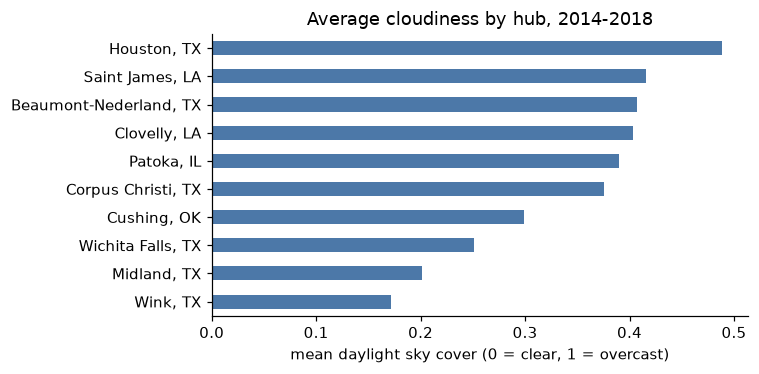

In [6]:
ax = hourly.mean().sort_values().plot.barh(figsize=(7, 3.5), color="#4C78A8")
ax.set_xlabel("mean daylight sky cover (0 = clear, 1 = overcast)")
ax.set_title(f"Average cloudiness by hub, {C.START_YEAR}-{C.END_YEAR}")
plt.tight_layout(); plt.show()

**`daily_cloudiness.csv`** is the ten-hub average per day. This is the series behind the paper's Table 1 row *Daily cloudiness*.

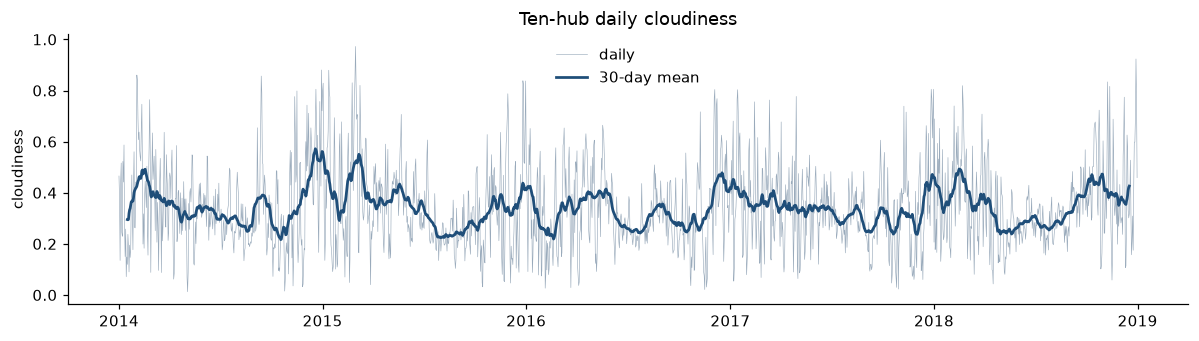

,ours,paper (2014-18)
mean,0.342,0.35
median,0.317,0.33
sd,0.162,0.16
obs,1826.000,1826.00


In [7]:
daily = pd.read_csv(C.OUT / "daily_cloudiness.csv", index_col="date", parse_dates=True)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(daily.index, daily.cloudiness, lw=0.4, color="#9ab", label="daily")
ax.plot(daily.index, daily.cloudiness.rolling(30, center=True).mean(), lw=1.8, color="#1f4e79", label="30-day mean")
ax.set_ylabel("cloudiness"); ax.legend(frameon=False); ax.set_title("Ten-hub daily cloudiness")
plt.tight_layout(); plt.show()

paper = {"mean": 0.35, "median": 0.33, "sd": 0.16, "obs": 1826}   # paper's Table 1, 2014-2018
pd.DataFrame({"ours": [daily.cloudiness.mean(), daily.cloudiness.median(), daily.cloudiness.std(), daily.cloudiness.notna().sum()],
              "paper (2014-18)": list(paper.values())}, index=list(paper)).round(3)

**`weekly_cloudiness.csv`** has one row per EIA announcement date, with the weekly cloudiness and the `cloudy` dummy. This is the instrument we will interact with the oil inventory surprise (regression Eq. 1 in the paper). The `announcement` column assumes every Wednesday for now; holiday-delayed releases need the EIA calendar.

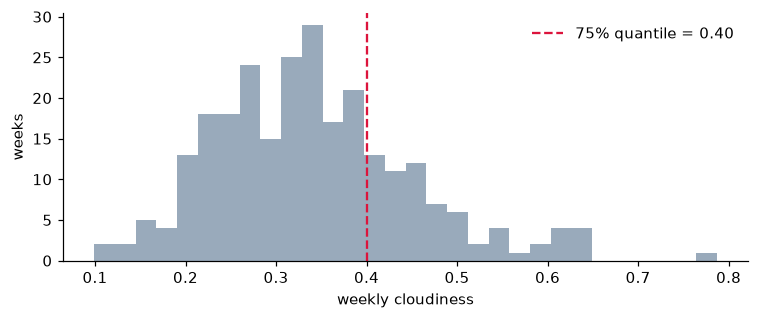

261 weeks, 65 cloudy, 196 clear


,announcement,cloudiness,n_days,cloudy
5,2014-02-05,0.585646,6,1
6,2014-02-12,0.611811,6,1
8,2014-02-26,0.450954,6,1
9,2014-03-05,0.420676,6,1
14,2014-04-09,0.412995,6,1


In [8]:
weekly = pd.read_csv(C.OUT / "weekly_cloudiness.csv", parse_dates=["announcement"])
thr = weekly.cloudiness.quantile(C.CLOUDY_QUANTILE)

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(weekly.cloudiness.dropna(), bins=30, color="#9ab")
ax.axvline(thr, color="crimson", ls="--", label=f"{C.CLOUDY_QUANTILE:.0%} quantile = {thr:.2f}")
ax.set_xlabel("weekly cloudiness"); ax.set_ylabel("weeks"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print(f"{len(weekly)} weeks, {weekly.cloudy.sum()} cloudy, {(weekly.cloudy == 0).sum()} clear")
weekly[weekly.cloudy == 1].head()

## 4. What does "cloudy" look like from space?

We now pick days where the airport reading and the satellite should agree, and look at them. Two free sources, no login needed:
- **NASA GIBS (MODIS Terra, 250 m)** for the regional view: any day since 2000, ten hubs. Defined in `viz.gibs_true_color`.
- **Sentinel-2 (10 m)** for the Cushing tank farm close-up, like the paper's Fig. 1. Defined in `viz.s2_search` / `viz.s2_chip`. Only available every ~5 days.

First: Cushing-only daily cloudiness from the airport station, and the list of Sentinel-2 scenes over Cushing.

In [9]:
HUB = "Cushing, OK"
_, hub_lat, hub_lon = C.HUBS[HUB]

# Cushing-only daily cloudiness (same rule as the ten-hub series: >= 6 daylight hours)
h = hourly[HUB]
day = h.index.floor("D")
cush = h.groupby(day).mean().where(h.notna().groupby(day).sum() >= C.MIN_HOURS_PER_DAY)

# Sentinel-2 scenes covering Cushing in the sample (cloud cover is measured by ESA over the whole 110 km scene)
items = viz.s2_search(hub_lat, hub_lon, f"{C.START_YEAR}-01-01", f"{C.END_YEAR}-12-31")
by_date = {}                                   # several (overlapping) scenes can exist for one day
for it in items:
    by_date.setdefault(pd.Timestamp(it["properties"]["datetime"][:10]), []).append(it)
best = {d: max(v, key=lambda i: viz.bbox_margin(i, hub_lat, hub_lon)) for d, v in by_date.items()}
s2 = pd.DataFrame({"s2_cloud_pct": {d: i["properties"]["eo:cloud_cover"] for d, i in best.items()}})
s2["airport"] = cush.reindex(s2.index)
s2 = s2.dropna(subset=["airport"])
print(len(s2), "Sentinel-2 dates with an airport reading")

85 Sentinel-2 dates with an airport reading


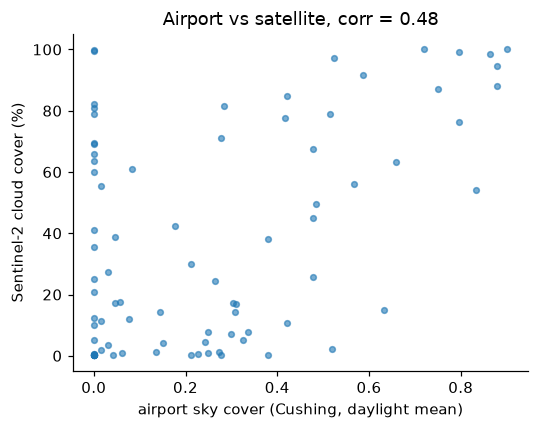

In [10]:
# Does the airport sky reading agree with the satellite's own cloud estimate?
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(s2.airport, s2.s2_cloud_pct, s=14, alpha=0.6)
ax.set_xlabel("airport sky cover (Cushing, daylight mean)"); ax.set_ylabel("Sentinel-2 cloud cover (%)")
ax.set_title(f"Airport vs satellite, corr = {s2.airport.corr(s2.s2_cloud_pct):.2f}")
plt.tight_layout(); plt.show()

Pick one clear and one cloudy day (airport and satellite both agree), then show the regional MODIS view of each.

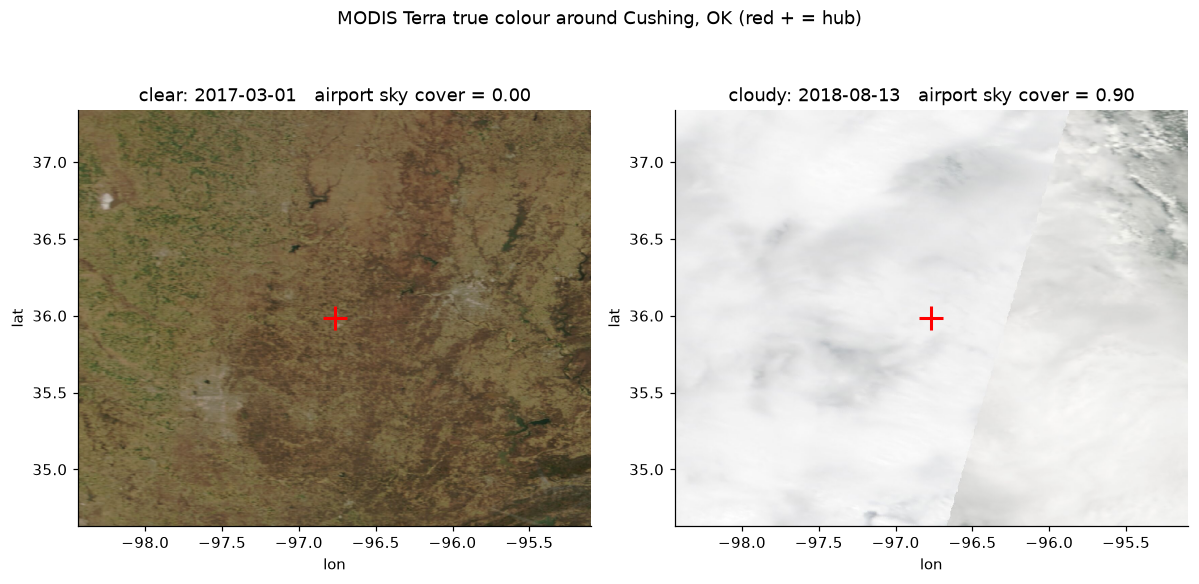

In [11]:
clear_day = s2[s2.s2_cloud_pct < 5].airport.idxmin()
cloudy_day = s2[s2.s2_cloud_pct > 70].airport.idxmax()
days = {"clear": clear_day, "cloudy": cloudy_day}

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (name, d) in zip(axes, days.items()):
    img, (w, s, e, n) = viz.gibs_true_color(hub_lat, hub_lon, d.date(), half_km=150)
    ax.imshow(img, extent=(w, e, s, n))
    ax.plot(hub_lon, hub_lat, "r+", ms=16, mew=2)
    ax.set_title(f"{name}: {d.date()}   airport sky cover = {s2.airport[d]:.2f}")
    ax.set_xlabel("lon"); ax.set_ylabel("lat")
fig.suptitle("MODIS Terra true colour around Cushing, OK (red + = hub)")
plt.tight_layout(); plt.show()

Same cloudy day, **all ten hubs** (150 km boxes). The number is each hub's airport sky reading that day, so you can check station vs picture.

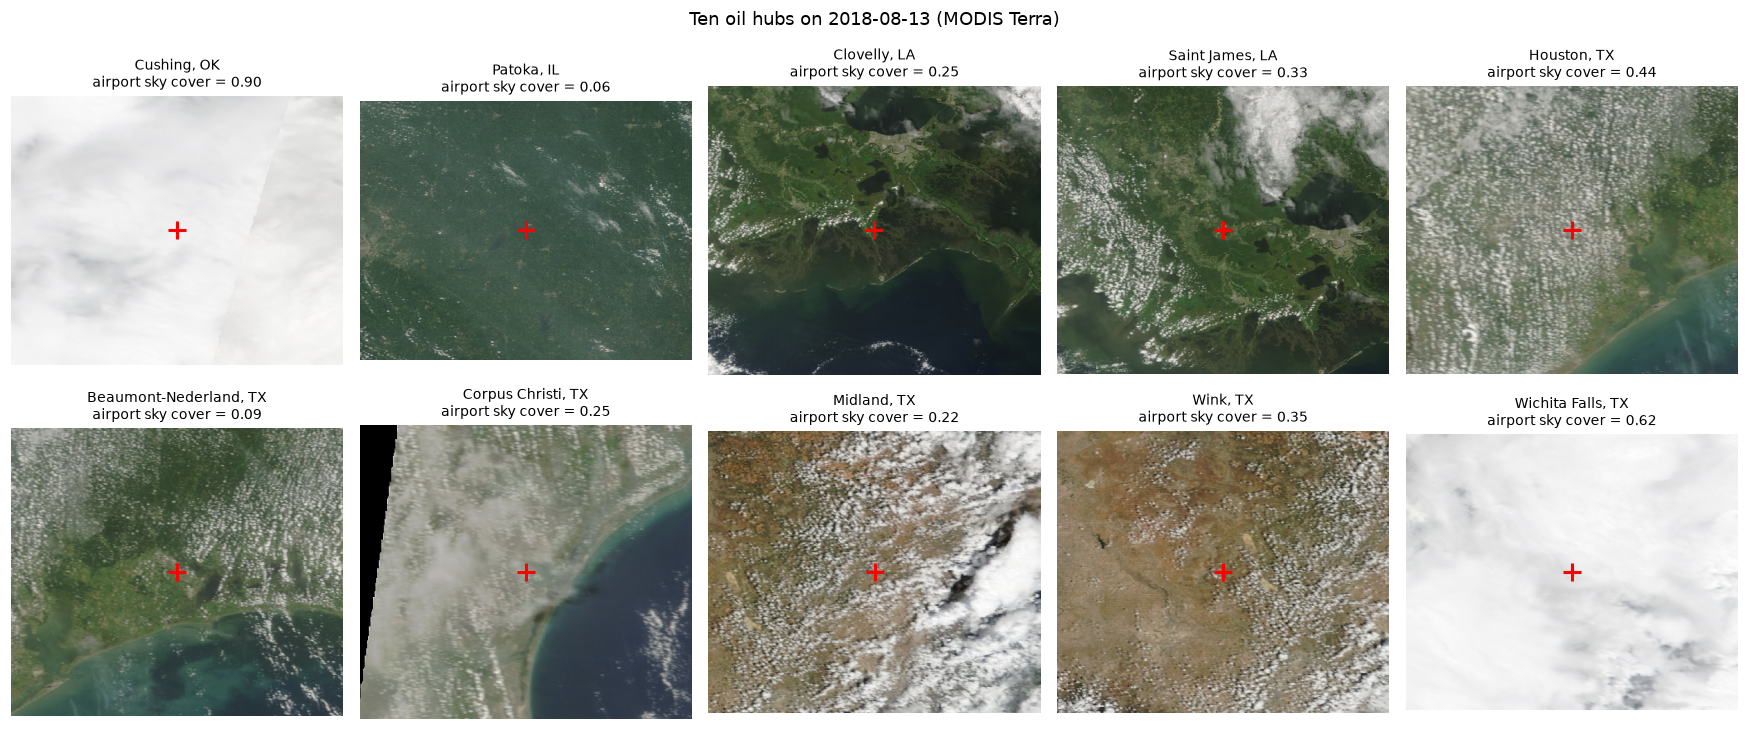

In [12]:
d = cloudy_day
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (hub, (_, lat, lon)) in zip(axes.ravel(), C.HUBS.items()):
    img, (w, s, e, n) = viz.gibs_true_color(lat, lon, d.date(), half_km=100, px=400)
    ax.imshow(img, extent=(w, e, s, n)); ax.plot(lon, lat, "r+", ms=12, mew=2)
    hd = hourly[hub]; v = hd[hd.index.floor("D") == d].mean()
    ax.set_title(f"{hub}\nairport sky cover = {v:.2f}", fontsize=9); ax.axis("off")
fig.suptitle(f"Ten oil hubs on {d.date()} (MODIS Terra)")
plt.tight_layout(); plt.show()

**Sentinel-2 close-up of the Cushing tank farm** (10 km box), the same clear-vs-cloudy contrast as the paper's Fig. 1. On the clear day the floating-roof tanks and their inner shadows are visible, which is what private satellites measure. Under cloud they are not.

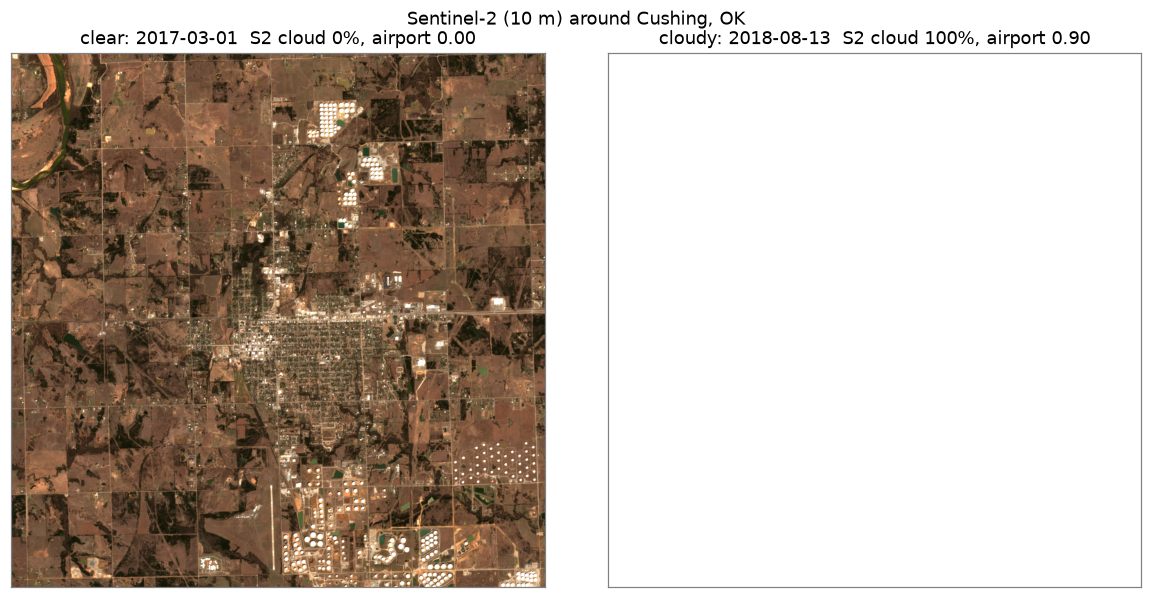

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
for ax, (name, d) in zip(axes, days.items()):
    item, chip = viz.s2_best_chip(by_date[d], hub_lat, hub_lon, half_km=5)
    ax.imshow(chip); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color("0.5")   # frame, so an all-white cloudy image is visible
    ax.set_title(f"{name}: {d.date()}  S2 cloud {item['properties']['eo:cloud_cover']:.0f}%, airport {s2.airport[d]:.2f}")
fig.suptitle("Sentinel-2 (10 m) around Cushing, OK")
plt.tight_layout(); plt.show()

## 5. How to use this / what is next

**Use the data in your own analysis**
```python
import pandas as pd, config as C
weekly = pd.read_csv(C.OUT / "weekly_cloudiness.csv", parse_dates=["announcement"])   # merge on `announcement`
```
Join it with the EIA inventory surprise and oil returns on `announcement`, then run Eq. (1): `ret = a + b_clear*dInv*Clear + b_cloudy*dInv*Cloudy`.

**Re-run for another period** (e.g. the paper's pre-period): edit `START_YEAR`/`END_YEAR` in `config.py`, then
```
python 01_select_stations.py
python 02_download_isd.py 1            # add rank 2/3 or a hub name if a station fails: 02_download_isd.py 3 houston
python 03_cloudiness.py                # prints QC; stations under 80% sky completeness are skipped
```
`data/` is git-ignored (≈ 700 MB of raw ISD files), so each person re-downloads it with step 2.

**Still to do**
- EIA weekly inventories (`WCESTUS1`) and the release calendar with holiday delays
- OVX implied volatility
- 15-minute WTI futures prices, the main blocker (tick data access)
- Orbital Insight and API estimates are proprietary, so we skip them